In [1]:
import pandas as pd
df=pd.read_csv("train.csv")

In [2]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [4]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.describe()

,Row ID,Postal Code,Sales
count,9800.000000,9789.000000,9800.000000
mean,4900.500000,55273.322403,230.769059
std,2829.160653,32041.223413,626.651875
min,1.000000,1040.000000,0.444000
25%,2450.750000,23223.000000,17.248000
50%,4900.500000,58103.000000,54.490000
75%,7350.250000,90008.000000,210.605000
max,9800.000000,99301.000000,22638.480000


In [7]:
df.shape

(9800, 18)

In [8]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales'],
      dtype='str')

In [9]:
df.dtypes

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code      float64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
dtype: object

In [10]:
print(df.duplicated().sum())

0


In [11]:
# Business Question 1 - What is the total sales of the company?
total_sales=df["Sales"].sum()
print("Total_sales",total_sales)

Total_sales 2261536.7827


In [12]:
# What is the average sales per order?
avg_sales = df["Sales"].mean()
print("Average_Sales",avg_sales)

Average_Sales 230.76905945918367


In [13]:
# Highest Sale
Highest_sales=df["Sales"].max()
print("Highest_Sales",Highest_sales)

Highest_Sales 22638.48


In [14]:
# Lowest Sale
Lowest_Sales=df["Sales"].min()
print("Lowest_Sales",Lowest_Sales)

Lowest_Sales 0.444


In [15]:
# Total Orders
Total_Order=df["Order ID"].nunique()
print("Total_Orders: ",Total_Order)

Total_Orders:  4922


In [16]:
#Total Customers
Total_Cust=df["Customer ID"].nunique()
print("Total_Customer: ",Total_Cust)


Total_Customer:  793


In [17]:
# Total Products
Total_Prod=df["Product ID"].nunique()
print(f"Total Products   : {Total_Prod}")

Total Products   : 1861


In [18]:
# "Which region generated the highest total sales?"
region_sales=df.groupby("Region")["Sales"].sum()
print(region_sales)

Region
Central    492646.9132
East       669518.7260
South      389151.4590
West       710219.6845
Name: Sales, dtype: float64


In [19]:
# To find the highest-selling region, you can sort the result:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

print(region_sales)

Region
West       710219.6845
East       669518.7260
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64


In [20]:
Highest_sales=df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print(Highest_sales)
#Business Insight: Technology is the highest revenue-generating category. 
#The company should continue investing in technology products because 
#they contribute the most to total sales.

Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64


In [21]:
# "I don't just want the total sales. 
#I also want to know how many orders each category received."
category_summary=df.groupby("Category").agg(
    total_Sales=("Sales","sum"),
    total_Order=("Order ID","count"))
print(category_summary)

                 total_Sales  total_Order
Category                                 
Furniture        728658.5757         2078
Office Supplies  705422.3340         5909
Technology       827455.8730         1813


In [22]:
# Your manager says:"I want a report showing the performance of each region."
Region_Performance=df.groupby("Region").agg(
    Total_sales=("Sales","sum"),
    Average_Sales=("Sales","mean"),
    Highest_Sales=("Sales","max"),
    Number_Of_Orders=("Order ID","count"))
print(Region_Performance)

         Total_sales  Average_Sales  Highest_Sales  Number_Of_Orders
Region                                                              
Central  492646.9132     216.357889      17499.950              2277
East     669518.7260     240.401697      11199.968              2785
South    389151.4590     243.524067      22638.480              1598
West     710219.6845     226.184613      13999.960              3140


In [23]:
Region_Performance = Region_Performance.sort_values(
    by="Total_sales",
    ascending=False
)

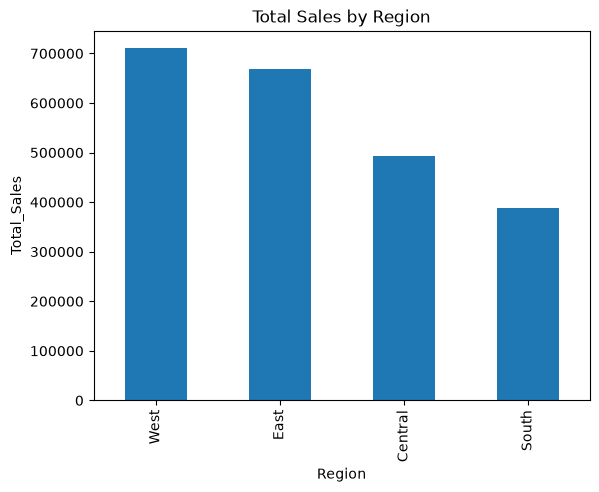

In [24]:
import matplotlib.pyplot as plt
Region_Performance["Total_sales"].plot(kind="bar")
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total_Sales")
plt.show()          

In [25]:
#Category Performance
#Total Sales
#Average Sales
#Highest Sale
#Total Orders

Category_Performance=df.groupby("Category").agg(
    Total_Sale=("Sales","sum"),
    Average_Sale=("Sales","mean"),
    Highest_Sale=("Sales","max"),
    Total_Order=("Order ID","nunique")).sort_values(by="Total_Sale",ascending=False)    
print(Category_Performance)

                  Total_Sale  Average_Sale  Highest_Sale  Total_Order
Category                                                             
Technology       827455.8730    456.401474     22638.480         1519
Furniture        728658.5757    350.653790      4416.174         1727
Office Supplies  705422.3340    119.381001      9892.740         3676


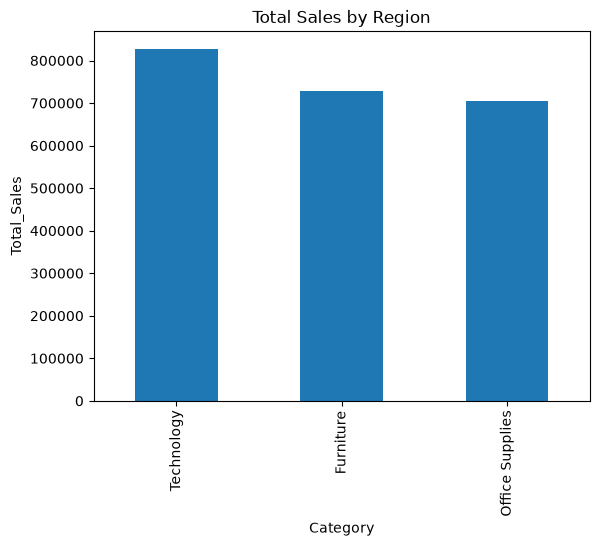

In [26]:
Category_Performance["Total_Sale"].plot(kind="bar")
plt.title("Total Sales by Region")
plt.xlabel("Category")
plt.ylabel("Total_Sales")
plt.show()

In [27]:
#Segment Performance
#Total Sales
#Average Sales
#Highest Sale
#Total Orders

Segment_Performance=df.groupby("Segment").agg(
    Total_Sale=("Sales","sum"),
    Average_Sales=("Sales","mean"),
    Highest_Sale=("Sales","max"),
    Total_Order=("Order ID","nunique")).sort_values(by="Total_Sale",ascending=False)
print(Segment_Performance)

               Total_Sale  Average_Sales  Highest_Sale  Total_Order
Segment                                                            
Consumer     1.148061e+06     225.065777      13999.96         2537
Corporate    6.884941e+05     233.150720      17499.95         1491
Home Office  4.249822e+05     243.403309      22638.48          894


In [28]:
#State Performance
#Total Sales
#Average Sales
#Highest Sale
#Total Orders

State_Performance=df.groupby("State").agg(
    Total_Sale=("Sales","sum"),
    Average_Sales=("Sales","mean"),
    Highest_Sale=("Sales","max"),
    Total_Order=("Order ID","nunique")).sort_values(by="Total_Sale",ascending=False)
print(State_Performance)

                       Total_Sale  Average_Sales  Highest_Sale  Total_Order
State                                                                      
California            446306.4635     229.345562      8187.650         1002
New York              306361.1470     279.271784     11199.968          547
Texas                 168572.5322     173.250290      8159.952          480
Washington            135206.8500     268.267560     13999.960          254
Pennsylvania          116276.6500     199.788058      8399.976          285
Florida                88436.5320     237.095260     22638.480          197
Illinois               79236.5170     164.050760      2799.960          270
Michigan               76136.0740     300.933099      9892.740          116
Ohio                   75130.3500     165.485352      4499.985          227
Virginia               70636.7200     315.342500      8749.950          115
North Carolina         55165.9640     223.343984      7999.980          134
Indiana     

In [29]:
# Create a report showing the Top 10 Products by Total Sales.
Top_product=df.groupby("Product Name").agg(
    Total_Sales=("Sales","sum")).sort_values(by="Total_Sales",ascending=False)
print(Top_product.head(10))


                                                    Total_Sales
Product Name                                                   
Canon imageCLASS 2200 Advanced Copier                 61599.824
Fellowes PB500 Electric Punch Plastic Comb Bind...    27453.384
Cisco TelePresence System EX90 Videoconferencin...    22638.480
HON 5400 Series Task Chairs for Big and Tall          21870.576
GBC DocuBind TL300 Electric Binding System            19823.479
GBC Ibimaster 500 Manual ProClick Binding System      19024.500
Hewlett Packard LaserJet 3310 Copier                  18839.686
HP Designjet T520 Inkjet Large Format Printer -...    18374.895
GBC DocuBind P400 Electric Binding System             17965.068
High Speed Automatic Electric Letter Opener           17030.312


In [30]:
# Bottom 10 Products by Sales
Bottom_product=df.groupby("Product Name").agg(
    Total_Sales=("Sales","sum")).sort_values(by="Total_Sales",ascending=True)
print(Bottom_product.head(10))


                                                    Total_Sales
Product Name                                                   
Eureka Disposable Bags for Sanitaire Vibra Groo...        1.624
Avery 5                                                   5.760
Xerox 20                                                  6.480
Grip Seal Envelopes                                       7.072
Acme Serrated Blade Letter Opener                         7.632
Avery Hi-Liter Pen Style Six-Color Fluorescent Set        7.700
Avery Hi-Liter Comfort Grip Fluorescent Highlig...        7.800
Xerox 1989                                                7.968
4009 Highlighters                                         8.040
Stockwell Gold Paper Clips                                8.096


In [31]:
# "Which customers generate the highest revenue?"
Top_Customer=df.groupby("Customer ID").agg(
    Total_Sales=("Sales","sum")).sort_values(by="Total_Sales",ascending=False).head(10)
print(Top_Customer)

             Total_Sales
Customer ID             
SM-20320       25043.050
TC-20980       19052.218
RB-19360       15117.339
TA-21385       14595.620
AB-10105       14473.571
KL-16645       14175.229
SC-20095       14142.334
HL-15040       12873.298
SE-20110       12209.438
CC-12370       12129.072


In [32]:
#Convert the column to a datetime type:
df["Order Date"]=pd.to_datetime(df["Order Date"],dayfirst=True)

In [33]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9800 non-null   int64         
 1   Order ID       9800 non-null   str           
 2   Order Date     9800 non-null   datetime64[us]
 3   Ship Date      9800 non-null   str           
 4   Ship Mode      9800 non-null   str           
 5   Customer ID    9800 non-null   str           
 6   Customer Name  9800 non-null   str           
 7   Segment        9800 non-null   str           
 8   Country        9800 non-null   str           
 9   City           9800 non-null   str           
 10  State          9800 non-null   str           
 11  Postal Code    9789 non-null   float64       
 12  Region         9800 non-null   str           
 13  Product ID     9800 non-null   str           
 14  Category       9800 non-null   str           
 15  Sub-Category   9800 non-null   s

In [34]:
# Extract month number
df["Month"]=df["Order Date"].dt.month

In [35]:
print(df[["Order Date", "Month"]].head())

  Order Date  Month
0 2017-11-08     11
1 2017-11-08     11
2 2017-06-12      6
3 2016-10-11     10
4 2016-10-11     10


In [36]:
# Extract month number
# column creation
df["Year"]=df["Order Date"].dt.year

In [37]:
print(df[["Order Date","Year"]].head())

  Order Date  Year
0 2017-11-08  2017
1 2017-11-08  2017
2 2017-06-12  2017
3 2016-10-11  2016
4 2016-10-11  2016


In [38]:
print(df[["Month","Year"]])
print("Month","Year")

      Month  Year
0        11  2017
1        11  2017
2         6  2017
3        10  2016
4        10  2016
...     ...   ...
9795      5  2017
9796      1  2016
9797      1  2016
9798      1  2016
9799      1  2016

[9800 rows x 2 columns]
Month Year


In [39]:
# What are the total sales for each month
Monthly_Sales=df.groupby("Month").agg(
    Total_Sales=("Sales","sum"))

print(Monthly_Sales)

       Total_Sales
Month             
1       94291.6296
2       59371.1154
3      197573.5872
4      136283.0006
5      154086.7237
6      145837.5233
7      145535.6890
8      157315.9270
9      300103.4117
10     199496.2947
11     350161.7110
12     321480.1695


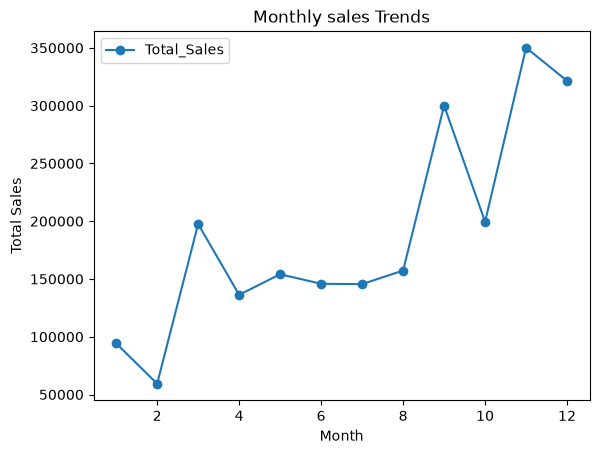

In [40]:
# How do sales change month by month?
# Monthly Sales Trend.
import matplotlib.pyplot as plt
Monthly_Sales.plot(kind="line",marker = "o")
plt.title("Monthly sales Trends")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.show()

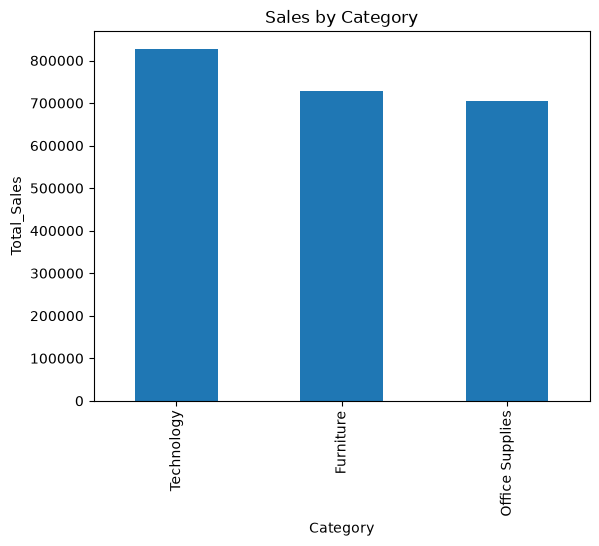

In [41]:
Category_Performance["Total_Sale"].plot(kind="bar")
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total_Sales")
plt.show()

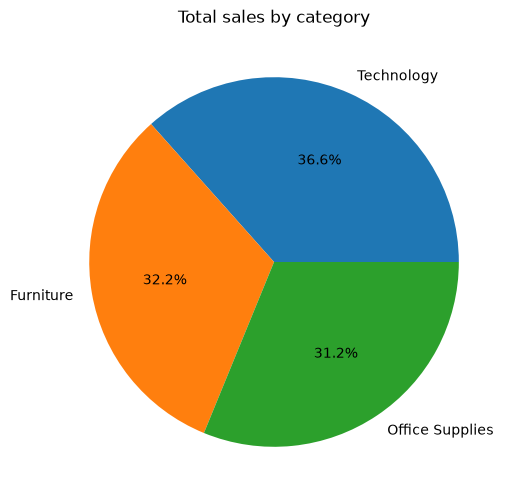

In [42]:
# What percentage of total sales comes from each category?
Category_Performance["Total_Sale"].plot(
    kind="pie",
    autopct="%1.1f%%",# Show percentages
    figsize=(6,6))
plt.title("Total sales by category")
plt.show()

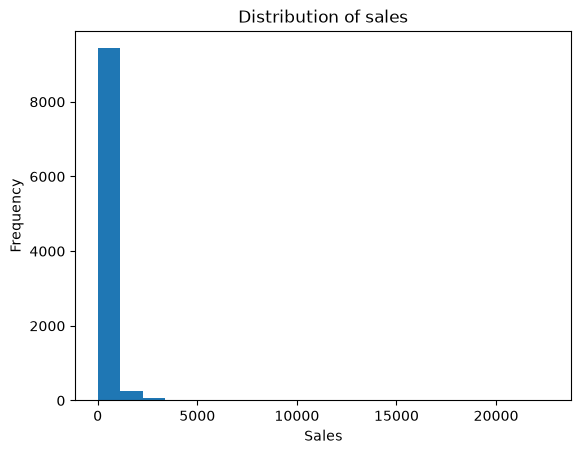

In [43]:
#"How are the sales values distributed?"
df["Sales"].plot(kind="hist",bins=20)
plt.title("Distribution of sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

In [44]:
# Bottom 10 Customers by Sales
Bottom_Customer=df.groupby(["Customer ID","Customer Name"]).agg(
    Total_Sales=("Sales","sum")).sort_values(by="Total_Sales",ascending=True).head(10)
print(Bottom_Customer)


                             Total_Sales
Customer ID Customer Name               
TS-21085    Thais Sissman          4.833
LD-16855    Lela Donovan           5.304
SC-20845    Sung Chung            14.112
CJ-11875    Carl Jackson          16.520
MG-18205    Mitch Gastineau       16.739
RS-19870    Roy Skaria            22.328
SG-20890    Susan Gilcrest        47.946
RE-19405    Ricardo Emerson       48.360
IM-15055    Ionia McGrath         48.400
LB-16735    Larry Blacks          50.188


In [45]:
#Who are our most valuable customers?
#Create a report with:Customer ID,Customer Name,Total Sales,Average Sales,Number of Orders,Sort by Total Sales (descending).
Valuable_Customer=df.groupby(["Customer ID","Customer Name"]).agg(
    Total_Sales=("Sales","sum"),
    Average_Sales=("Sales","mean"),
    Number_Of_Orders=("Order ID","nunique")
).sort_values(by="Total_Sales",ascending=False).head(20)
print(Valuable_Customer)

                                Total_Sales  Average_Sales  Number_Of_Orders
Customer ID Customer Name                                                   
SM-20320    Sean Miller           25043.050    1669.536667                 5
TC-20980    Tamara Chand          19052.218    1587.684833                 5
RB-19360    Raymond Buch          15117.339     839.852167                 6
TA-21385    Tom Ashbrook          14595.620    1459.562000                 4
AB-10105    Adrian Barton         14473.571     723.678550                10
KL-16645    Ken Lonsdale          14175.229     488.801000                12
SC-20095    Sanjit Chand          14142.334     642.833364                 9
HL-15040    Hunter Lopez          12873.298    1170.299818                 6
SE-20110    Sanjit Engle          12209.438     642.602000                11
CC-12370    Christopher Conant    12129.072    1102.642909                 5
TS-21370    Todd Sumrall          11891.751     792.783400                 6

In [46]:
# "Who spends the most money per order?" AOV
Valuable_Customer["AOV"]=(Valuable_Customer["Total_Sales"]/Valuable_Customer["Number_Of_Orders"])
print(Valuable_Customer.head())


                           Total_Sales  Average_Sales  Number_Of_Orders  \
Customer ID Customer Name                                                 
SM-20320    Sean Miller      25043.050    1669.536667                 5   
TC-20980    Tamara Chand     19052.218    1587.684833                 5   
RB-19360    Raymond Buch     15117.339     839.852167                 6   
TA-21385    Tom Ashbrook     14595.620    1459.562000                 4   
AB-10105    Adrian Barton    14473.571     723.678550                10   

                                 AOV  
Customer ID Customer Name             
SM-20320    Sean Miller    5008.6100  
TC-20980    Tamara Chand   3810.4436  
RB-19360    Raymond Buch   2519.5565  
TA-21385    Tom Ashbrook   3648.9050  
AB-10105    Adrian Barton  1447.3571  


In [47]:
Top_AOV_Customer=Valuable_Customer.sort_values(by="AOV",ascending=False).head(10)
print(Top_AOV_Customer)

                                Total_Sales  Average_Sales  Number_Of_Orders  \
Customer ID Customer Name                                                      
SM-20320    Sean Miller           25043.050    1669.536667                 5   
TC-20980    Tamara Chand          19052.218    1587.684833                 5   
TA-21385    Tom Ashbrook          14595.620    1459.562000                 4   
BM-11140    Becky Martin          11789.630     736.851875                 4   
RB-19360    Raymond Buch          15117.339     839.852167                 6   
CC-12370    Christopher Conant    12129.072    1102.642909                 5   
HL-15040    Hunter Lopez          12873.298    1170.299818                 6   
BS-11365    Bill Shonely          10501.653    1166.850333                 5   
TS-21370    Todd Sumrall          11891.751     792.783400                 6   
SC-20095    Sanjit Chand          14142.334     642.833364                 9   

                                       

In [48]:
# 🎯 Task: Sales by Ship Mode
# "Which shipping mode generates the highest sales?"
Ship_Mode=df.groupby("Ship Mode").agg(
    Total_Sales=("Sales","sum"),
    Average_Sales=("Sales","mean"),
    No_of_Orders=("Order ID","nunique")

).sort_values(by="Total_Sales",ascending=False)
print(Ship_Mode)

                 Total_Sales  Average_Sales  No_of_Orders
Ship Mode                                                
Standard Class  1.340831e+06     228.849856          2945
Second Class    4.499142e+05     236.547939           944
First Class     3.455723e+05     230.228020           772
Same Day        1.252190e+05     232.749143           261


In [49]:
# Which Region and Category combination generates the highest sales?
Highest_Sales=df.groupby(["Region","Category"]).agg(
    Total_Sales=("Sales","sum"),
    Average_Sales=("Sales","mean"),
    Number_of_Orders=("Order ID","nunique")
).sort_values(by="Total_Sales",ascending=False)
print(Highest_Sales)

                         Total_Sales  Average_Sales  Number_of_Orders
Region  Category                                                     
East    Technology       263116.5270     499.272347               436
West    Technology       247404.9300     420.042326               483
        Furniture        245348.2455     355.062584               582
        Office Supplies  217466.5090     116.917478              1150
East    Furniture        206461.3880     349.342450               480
        Office Supplies  199940.8110     119.940499              1048
Central Technology       168739.2080     413.576490               348
        Office Supplies  163590.2430     116.933698               865
        Furniture        160317.4622     341.100983               393
South   Technology       148195.2080     512.786187               252
        Office Supplies  124424.7710     126.576573               613
        Furniture        116531.4800     357.458528               272


In [50]:
#"Which region performs best within each customer segment?"
Best_Performance=df.groupby(["Region","Segment"]).agg(
    Total_Sales=("Sales","sum"),
    Average_Sales=("Sales","mean"),
    Number_of_Orders=("Order ID","nunique")
).sort_values(by="Total_Sales",ascending=False)
print(Best_Performance)

                     Total_Sales  Average_Sales  Number_of_Orders
Region  Segment                                                  
West    Consumer     355241.1910     216.874964               811
East    Consumer     347906.6050     240.932552               698
Central Consumer     250210.5220     210.614918               590
West    Corporate    220018.2785     233.565051               478
East    Corporate    195897.4250     230.467559               424
South   Consumer     194702.2130     234.298692               438
Central Corporate    152031.4968     230.002264               345
West    Home Office  134960.2150     241.000384               298
East    Home Office  125714.6960     256.038077               247
South   Corporate    120546.8745     241.093749               244
Central Home Office   90404.8944     211.226389               221
South   Home Office   73902.3715     276.787908               128


In [51]:
# Which region has the highest average order value?
Best_Performance["AOV"]=Best_Performance["Total_Sales"]/Best_Performance["Number_of_Orders"]
print(Best_Performance)

                     Total_Sales  Average_Sales  Number_of_Orders         AOV
Region  Segment                                                              
West    Consumer     355241.1910     216.874964               811  438.028596
East    Consumer     347906.6050     240.932552               698  498.433532
Central Consumer     250210.5220     210.614918               590  424.085631
West    Corporate    220018.2785     233.565051               478  460.289286
East    Corporate    195897.4250     230.467559               424  462.022229
South   Consumer     194702.2130     234.298692               438  444.525600
Central Corporate    152031.4968     230.002264               345  440.671005
West    Home Office  134960.2150     241.000384               298  452.886628
East    Home Office  125714.6960     256.038077               247  508.966381
South   Corporate    120546.8745     241.093749               244  494.044568
Central Home Office   90404.8944     211.226389               22

In [52]:
Best_Performance=Best_Performance.sort_values(by="AOV",ascending=False)
print(Best_Performance)

                     Total_Sales  Average_Sales  Number_of_Orders         AOV
Region  Segment                                                              
South   Home Office   73902.3715     276.787908               128  577.362277
East    Home Office  125714.6960     256.038077               247  508.966381
        Consumer     347906.6050     240.932552               698  498.433532
South   Corporate    120546.8745     241.093749               244  494.044568
East    Corporate    195897.4250     230.467559               424  462.022229
West    Corporate    220018.2785     233.565051               478  460.289286
        Home Office  134960.2150     241.000384               298  452.886628
South   Consumer     194702.2130     234.298692               438  444.525600
Central Corporate    152031.4968     230.002264               345  440.671005
West    Consumer     355241.1910     216.874964               811  438.028596
Central Consumer     250210.5220     210.614918               59

In [53]:
# Show all orders where Sales are greater than 500."
#And display only these columns:
#Order ID
#Customer Name
#Category
#Sales
df[df["Sales"] > 500][
    ["Order ID", "Customer Name", "Category", "Sales"]
].head(5)

,Order ID,Customer Name,Category,Sales
1,CA-2017-152156,Claire Gute,Furniture,731.9400
3,US-2016-108966,Sean O'Donnell,Furniture,957.5775
7,CA-2015-115812,Brosina Hoffman,Technology,907.1520
10,CA-2015-115812,Brosina Hoffman,Furniture,1706.1840
11,CA-2015-115812,Brosina Hoffman,Technology,911.4240


In [54]:
# Show orders where Sales are greater than 500 AND Category is Technology.
df[(df["Sales"]>500)&(df["Category"]=="Technology")].head(10)
                                                

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Month,Year
7,8,CA-2015-115812,2015-06-09,14/06/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,TEC-PH-10002275,Technology,Phones,Mitel 5320 IP Phone VoIP phone,907.152,6,2015
11,12,CA-2015-115812,2015-06-09,14/06/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,TEC-PH-10002033,Technology,Phones,Konftel 250 Conference phone - Charcoal black,911.424,6,2015
35,36,CA-2017-117590,2017-12-08,10/12/2017,First Class,GH-14485,Gene Hale,Corporate,United States,Richardson,Texas,75080.0,Central,TEC-PH-10004977,Technology,Phones,GE 30524EE4,1097.544,12,2017
54,55,CA-2017-105816,2017-12-11,17/12/2017,Standard Class,JM-15265,Janet Molinari,Corporate,United States,New York City,New York,10024.0,East,TEC-PH-10002447,Technology,Phones,AT&T CL83451 4-Handset Telephone,1029.950,12,2017
159,160,CA-2017-114104,2017-11-20,24/11/2017,Standard Class,NP-18670,Nora Paige,Consumer,United States,Edmond,Oklahoma,73034.0,Central,TEC-PH-10004536,Technology,Phones,Avaya 5420 Digital phone,944.930,11,2017
165,166,CA-2015-139892,2015-09-08,12/09/2015,Standard Class,BM-11140,Becky Martin,Consumer,United States,San Antonio,Texas,78207.0,Central,TEC-MA-10000822,Technology,Machines,Lexmark MX611dhe Monochrome Laser Printer,8159.952,9,2015
182,183,CA-2015-158274,2015-11-19,24/11/2015,Second Class,RM-19675,Robert Marley,Home Office,United States,Monroe,Louisiana,71203.0,South,TEC-PH-10003273,Technology,Phones,AT&T TR1909W,503.960,11,2015
215,216,CA-2016-146262,2016-01-02,09/01/2016,Standard Class,VW-21775,Victoria Wilson,Corporate,United States,Medina,Ohio,44256.0,East,TEC-MA-10000864,Technology,Machines,Cisco 9971 IP Video Phone Charcoal,1188.000,1,2016
235,236,US-2018-100930,2018-04-07,12/04/2018,Standard Class,CS-12400,Christopher Schild,Home Office,United States,Tampa,Florida,33614.0,South,TEC-AC-10003832,Technology,Accessories,Logitech P710e Mobile Speakerphone,617.976,4,2018
251,252,CA-2017-145625,2017-09-11,17/09/2017,Standard Class,KC-16540,Kelly Collister,Consumer,United States,San Diego,California,92037.0,West,TEC-AC-10003832,Technology,Accessories,Logitech P710e Mobile Speakerphone,3347.370,9,2017


In [55]:
# "Show orders where Category is either Technology OR Furniture."
#Also display only:
#Order ID
#Category
#Sales
df[
    (df["Category"] == "Technology") |
    (df["Category"] == "Furniture")
][["Order ID", "Category", "Sales"]].head(10)

,Order ID,Category,Sales
0,CA-2017-152156,Furniture,261.9600
1,CA-2017-152156,Furniture,731.9400
3,US-2016-108966,Furniture,957.5775
5,CA-2015-115812,Furniture,48.8600
7,CA-2015-115812,Technology,907.1520
10,CA-2015-115812,Furniture,1706.1840
11,CA-2015-115812,Technology,911.4240
19,CA-2015-143336,Technology,213.4800
23,US-2018-156909,Furniture,71.3720
24,CA-2016-106320,Furniture,1044.6300


In [56]:
# orders where Sales are between 500 and 1000, inclusive.
df[(df["Sales"]>=500) & (df["Sales"]<=1000)][["Order ID","Customer Name","Sales"]].head(10)

,Order ID,Customer Name,Sales
1,CA-2017-152156,Claire Gute,731.9400
3,US-2016-108966,Sean O'Donnell,957.5775
7,CA-2015-115812,Brosina Hoffman,907.1520
11,CA-2015-115812,Brosina Hoffman,911.4240
16,CA-2015-105893,Pete Kriz,665.8800
38,CA-2016-117415,Steve Nguyen,532.3992
72,US-2016-134026,Joel Eaton,831.9360
117,CA-2016-110457,Dave Kipp,787.5300
124,US-2015-152030,Alan Dominguez,600.5580
125,US-2015-134614,Philip Fox,617.7000


In [57]:
# orders where Sales are between 500 and 1000, inclusive.
# using Between
df[df["Sales"].between(500, 1000)][
    ["Order ID", "Customer Name", "Sales"]
].head(10)


,Order ID,Customer Name,Sales
1,CA-2017-152156,Claire Gute,731.9400
3,US-2016-108966,Sean O'Donnell,957.5775
7,CA-2015-115812,Brosina Hoffman,907.1520
11,CA-2015-115812,Brosina Hoffman,911.4240
16,CA-2015-105893,Pete Kriz,665.8800
38,CA-2016-117415,Steve Nguyen,532.3992
72,US-2016-134026,Joel Eaton,831.9360
117,CA-2016-110457,Dave Kipp,787.5300
124,US-2015-152030,Alan Dominguez,600.5580
125,US-2015-134614,Philip Fox,617.7000


In [58]:
#"How many orders were placed using each Ship Mode?"
df["Ship Mode"].value_counts()

Ship Mode
Standard Class    5859
Second Class      1902
First Class       1501
Same Day           538
Name: count, dtype: int64

In [59]:
# How many orders belong to each Category?
df["Category"].value_counts()

Category
Office Supplies    5909
Furniture          2078
Technology         1813
Name: count, dtype: int64

In [60]:
# value_counts() + percentage
# "What percentage of orders belong to each category?"
df["Category"].value_counts(normalize=True).mul(100).round(2)

Category
Office Supplies    60.3
Furniture          21.2
Technology         18.5
Name: proportion, dtype: float64

In [61]:
# pivot_table()
# "Show total sales for each Category across each Region."
df.pivot_table(index="Region",columns="Category",values="Sales",aggfunc="sum")

Category,Furniture,Office Supplies,Technology
Region,,,
Central,160317.4622,163590.243,168739.208
East,206461.3880,199940.811,263116.527
South,116531.4800,124424.771,148195.208
West,245348.2455,217466.509,247404.930


In [62]:
# "For each Region and Category, what are the total sales and average sales?"
df.pivot_table(index="Region",columns="Category",values="Sales",aggfunc=["sum","mean"])

sum                                    mean                  \
Category    Furniture Office Supplies  Technology   Furniture Office Supplies   
Region                                                                          
Central   160317.4622      163590.243  168739.208  341.100983      116.933698   
East      206461.3880      199940.811  263116.527  349.342450      119.940499   
South     116531.4800      124424.771  148195.208  357.458528      126.576573   
West      245348.2455      217466.509  247404.930  355.062584      116.917478   

                      
Category  Technology  
Region                
Central   413.576490  
East      499.272347  
South     512.786187  
West      420.042326

In [63]:
#merge()
employees = pd.DataFrame({
    "EmployeeID": [1, 2, 3, 4],
    "Name": ["A", "B", "C", "D"],
    "DepartmentID": [10, 20, 10, 30]
})

departments = pd.DataFrame({
    "DepartmentID": [10, 20, 30],
    "DepartmentName": ["IT", "HR", "Finance"]
})

In [64]:
pd.merge(
    employees,
    departments,
    on="DepartmentID",
    how="left"
)

,EmployeeID,Name,DepartmentID,DepartmentName
0,1,A,10,IT
1,2,B,20,HR
2,3,C,10,IT
3,4,D,30,Finance


In [65]:
pd.merge(
    employees,
    departments,
    on="DepartmentID",
    how="inner"
)

,EmployeeID,Name,DepartmentID,DepartmentName
0,1,A,10,IT
1,2,B,20,HR
2,3,C,10,IT
3,4,D,30,Finance


In [66]:
# Different Column Names
employees = pd.DataFrame({
    "EmployeeID": [1, 2, 3],
    "Name": ["A", "B", "C"],
    "DeptID": [10, 20, 10]
})

departments = pd.DataFrame({
    "DepartmentID": [10, 20, 30],
    "DepartmentName": ["IT", "HR", "Finance"]
})


In [67]:
pd.merge(
    employees,
    departments,
    left_on="DeptID",
    right_on="DepartmentID",
    how="left"
)

,EmployeeID,Name,DeptID,DepartmentID,DepartmentName
0,1,A,10,10,IT
1,2,B,20,20,HR
2,3,C,10,10,IT


In [68]:
#"Keep all departments, even if no employee belongs to them."
pd.merge(
    employees,
    departments,
    left_on="DeptID",
    right_on="DepartmentID",
    how="outer"
)

,EmployeeID,Name,DeptID,DepartmentID,DepartmentName
0,1.0,A,10.0,10,IT
1,3.0,C,10.0,10,IT
2,2.0,B,20.0,20,HR
3,NaN,NaN,NaN,30,Finance


In [69]:
# What percentage of orders belong to each customer segment?
df["Segment"].value_counts(normalize=True).mul(100).round(2)

Segment
Consumer       52.05
Corporate      30.13
Home Office    17.82
Name: proportion, dtype: float64

In [70]:
# map()->short labels
Category_Code={
    "Furniture":"F",
    "Office Supplies":"O",
    "Technology":"T"
}

df["Category_map"]=df["Category"].map(Category_Code)

In [71]:
df[["Category", "Category_map"]].head(10)

,Category,Category_map
0,Furniture,F
1,Furniture,F
2,Office Supplies,O
3,Furniture,F
4,Office Supplies,O
5,Furniture,F
6,Office Supplies,O
7,Technology,T
8,Office Supplies,O
9,Office Supplies,O


In [72]:
# apply()->For more complicated transformations based on calculations or conditions, we'll use apply().
def Sales_level(Sales):
    if Sales < 100:
        return "Low"
    elif Sales <=500:
        return "Medium"
    else:
        return "High"

df["Sales_level"]=df["Sales"].apply(Sales_level)
df["Sales_level"].value_counts()

Sales_level
Low       6101
Medium    2553
High      1146
Name: count, dtype: int64

In [73]:
# For each Sales Level, calculate Total Sales, Average Sales, and Number of Orders.
Each_Sales_level=df.groupby("Sales_level").agg(
    Total_Sales=("Sales","sum"),
    Average_Sales=("Sales","mean"),
    Number_of_Order=("Order ID","nunique")
).sort_values(by="Total_Sales",ascending=False)

print(Each_Sales_level)

              Total_Sales  Average_Sales  Number_of_Order
Sales_level                                              
High         1.455276e+06    1269.874043             1005
Medium       6.149440e+05     240.871125             2021
Low          1.913171e+05      31.358326             3791


In [74]:
# Which orders should be considered "Priority" based on Sales?
def Order_Priority(Sales):
    if Sales < 100:
        return "Normal"
    elif Sales <=500:
        return "Important"
    else:
        return "Priority"

df["Order_Priority"]=df["Sales"].apply(Order_Priority)
df["Order_Priority"].value_counts()

Order_Priority
Normal       6101
Important    2553
Priority     1146
Name: count, dtype: int64

In [75]:
df["Order Date"].dt.year

0       2017
1       2017
2       2017
3       2016
4       2016
        ... 
9795    2017
9796    2016
9797    2016
9798    2016
9799    2016
Name: Order Date, Length: 9800, dtype: int32

In [76]:
df["Year"]=df["Order Date"].dt.year

In [77]:
Yearly_Sales=df.groupby("Year").agg(
    Total_sales=("Sales","sum")
).sort_values(by="Total_sales",ascending=False)

print(Yearly_Sales)

      Total_sales
Year             
2018  722052.0192
2017  600192.5500
2015  479856.2081
2016  459436.0054


In [78]:
# Monthly Sales Analysis
# Which month generates the highest sales?

df["Month"]=df["Order Date"].dt.month
Monthly_sales=df.groupby(["Year","Month"]).agg(
    Total_Sales=("Sales","sum")
).sort_values(by="Total_Sales",ascending=False)

print(Monthly_Sales)

       Total_Sales
Month             
1       94291.6296
2       59371.1154
3      197573.5872
4      136283.0006
5      154086.7237
6      145837.5233
7      145535.6890
8      157315.9270
9      300103.4117
10     199496.2947
11     350161.7110
12     321480.1695


In [79]:
print(Monthly_sales.index.names)

['Year', 'Month']


In [80]:
df["Month_Name"] = df["Order Date"].dt.month_name()
print(df[["Order Date", "Month", "Month_Name"]].head(10))

  Order Date  Month Month_Name
0 2017-11-08     11   November
1 2017-11-08     11   November
2 2017-06-12      6       June
3 2016-10-11     10    October
4 2016-10-11     10    October
5 2015-06-09      6       June
6 2015-06-09      6       June
7 2015-06-09      6       June
8 2015-06-09      6       June
9 2015-06-09      6       June


In [81]:
Monthly_Sales = df.groupby(["Month", "Month_Name"]).agg(
    Total_Sales=("Sales", "sum")
).sort_values(
    by="Total_Sales",
    ascending=False
)

print(Monthly_Sales)

                  Total_Sales
Month Month_Name             
11    November    350161.7110
12    December    321480.1695
9     September   300103.4117
10    October     199496.2947
3     March       197573.5872
8     August      157315.9270
5     May         154086.7237
6     June        145837.5233
7     July        145535.6890
4     April       136283.0006
1     January      94291.6296
2     February     59371.1154


In [82]:
Monthly_Trend = df.groupby(["Month", "Month_Name"]).agg(
    Total_Sales=("Sales", "sum")
).sort_values(by="Month")

print(Monthly_Trend)

                  Total_Sales
Month Month_Name             
1     January      94291.6296
2     February     59371.1154
3     March       197573.5872
4     April       136283.0006
5     May         154086.7237
6     June        145837.5233
7     July        145535.6890
8     August      157315.9270
9     September   300103.4117
10    October     199496.2947
11    November    350161.7110
12    December    321480.1695


In [83]:
import importlib
import matplotlib.pyplot as plt

importlib.reload(plt)

<module 'matplotlib.pyplot' from 'C:\\Users\\Admin\\AppData\\Local\\Programs\\Python\\Python314\\Lib\\site-packages\\matplotlib\\pyplot.py'>

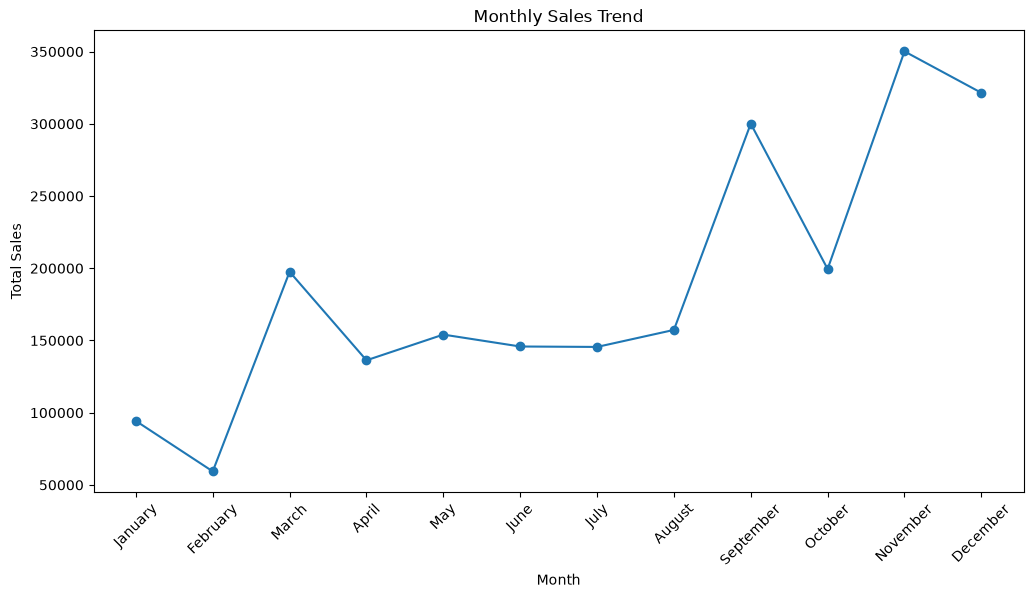

In [84]:
Monthly_Trend = Monthly_Trend.reset_index()

plt.figure(figsize=(12,6))

plt.plot(
    Monthly_Trend["Month_Name"],
    Monthly_Trend["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

In [85]:
# Monthly + Category Sales
# Which category performs best in each month?
Monthly_Category=df.groupby(["Month_Name","Category"]).agg(
    Total_Sales=("Sales","sum")
).sort_values(by="Total_Sales",ascending=False)

print(Monthly_Category)

                            Total_Sales
Month_Name Category                    
November   Technology       130497.1870
December   Furniture        121462.0255
November   Furniture        120508.8850
September  Furniture        104174.0847
           Office Supplies  101075.2780
December   Office Supplies  100026.7640
           Technology        99991.3800
November   Office Supplies   99155.6390
March      Technology        97500.3900
September  Technology        94854.0490
October    Technology        87031.9450
May        Technology        63450.1870
August     Office Supplies   61549.6880
October    Furniture         57665.8117
           Office Supplies   54798.5380
July       Technology        54131.3860
March      Office Supplies   53941.0850
August     Technology        51673.2560
June       Furniture         50168.4633
July       Furniture         48433.6720
April      Office Supplies   48298.8140
June       Technology        48180.7230
May        Furniture         48137.8707


In [86]:
# TO Find the BEST category in each month we can use idxmax().

Best_Category_Month = Monthly_Category.loc[              # .loc[...] → retrieves those rows from the original table.
                                                        # groupby(level="Month_Name")→ creates separate groups for January, February, March, etc.
    Monthly_Category.groupby(level="Month_Name")["Total_Sales"].idxmax() # ["Total_Sales"].idxmax()→ finds the row with the highest sales inside each month.
].sort_values(by="Total_Sales",ascending=False)

print(Best_Category_Month)


                            Total_Sales
Month_Name Category                    
November   Technology       130497.1870
December   Furniture        121462.0255
September  Furniture        104174.0847
March      Technology        97500.3900
October    Technology        87031.9450
May        Technology        63450.1870
August     Office Supplies   61549.6880
July       Technology        54131.3860
June       Furniture         50168.4633
April      Office Supplies   48298.8140
January    Office Supplies   33006.5810
February   Technology        23084.8420


In [87]:
Best_Category_Month = Best_Category_Month.reset_index()

In [88]:
Best_Category_Month["Category"].value_counts()

Category
Technology         6
Furniture          3
Office Supplies    3
Name: count, dtype: int64

In [89]:
# Sub-Category Analysis
# Which sub-categories generate the highest sales?
Category_Analysis=df.groupby("Sub-Category").agg(
    Total_Sales=("Sales","sum"),
    Average_Sales=("Sales","mean"),
    Number_Of_Orders=("Order ID","nunique")
).sort_values(by="Total_Sales",ascending=False)
print(Category_Analysis)

# Machines have only 115 orders but an average sale of ~1,645.55. 
# This teaches Highest total sales ≠ highest average order value.
# Similarly, Binders have the most orders (1,492) but aren't #1 in total sales

              Total_Sales  Average_Sales  Number_Of_Orders
Sub-Category                                              
Phones        327782.4480     374.180877               803
Chairs        322822.7310     531.833165               566
Storage       219343.3920     263.633885               764
Tables        202810.6280     645.893720               302
Binders       200028.7850     134.067550              1291
Machines      189238.6310    1645.553313               112
Accessories   164186.7000     217.178175               702
Copiers       146248.0940    2215.880212                66
Bookcases     113813.1987     503.598224               222
Appliances    104618.4030     227.926804               444
Furnishings    89212.0180      95.823865               855
Paper          76828.3040      57.420257              1163
Supplies       46420.3080     252.284283               181
Art            26705.4100      34.019631               720
Envelopes      16128.0460      65.032444               2

In [90]:
#Find the most valuable Sub-Category
Category_Analysis["AOV"]=(
    Category_Analysis["Total_Sales"]/
    Category_Analysis["Number_Of_Orders"]
)


print(Category_Analysis["AOV"])

Sub-Category
Phones          408.197320
Chairs          570.358182
Storage         287.098681
Tables          671.558371
Binders         154.940964
Machines       1689.630634
Accessories     233.884188
Copiers        2215.880212
Bookcases       512.672066
Appliances      235.627034
Furnishings     104.341542
Paper            66.060451
Supplies        256.465790
Art              37.090847
Envelopes        66.370560
Labels           36.316841
Fasteners        14.160189
Name: AOV, dtype: float64


In [91]:
SubCategory_performance=Category_Analysis.sort_values(by="AOV",ascending=False)
print(SubCategory_performance)

              Total_Sales  Average_Sales  Number_Of_Orders          AOV
Sub-Category                                                           
Copiers       146248.0940    2215.880212                66  2215.880212
Machines      189238.6310    1645.553313               112  1689.630634
Tables        202810.6280     645.893720               302   671.558371
Chairs        322822.7310     531.833165               566   570.358182
Bookcases     113813.1987     503.598224               222   512.672066
Phones        327782.4480     374.180877               803   408.197320
Storage       219343.3920     263.633885               764   287.098681
Supplies       46420.3080     252.284283               181   256.465790
Appliances    104618.4030     227.926804               444   235.627034
Accessories   164186.7000     217.178175               702   233.884188
Binders       200028.7850     134.067550              1291   154.940964
Furnishings    89212.0180      95.823865               855   104

In [92]:
# Customer Value Analysis
# Which customers have the highest Average Order Value (AOV)?#
####### complete customer report
Customer_Value = df.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Total_Sales=("Sales", "sum"),
    Number_Of_Orders=("Order ID", "nunique")
)

# AOV creation
Customer_Value["AOV"]=(
    Customer_Value["Total_Sales"]/
    Customer_Value["Number_Of_Orders"]
)
print(Customer_Value.head())
    

                           Total_Sales  Number_Of_Orders          AOV
Customer ID Customer Name                                            
AA-10315    Alex Avila        5563.560                 5  1112.712000
AA-10375    Allen Armold      1056.390                 9   117.376667
AA-10480    Andrew Allen      1790.512                 4   447.628000
AA-10645    Anna Andreadi     5086.935                 6   847.822500
AB-10015    Aaron Bergman      886.156                 3   295.385333


In [93]:
#top 10 customers by frequency
Customer_Value=Customer_Value.sort_values(by="Number_Of_Orders",ascending=False).head(10)
print(Customer_Value)

                                 Total_Sales  Number_Of_Orders         AOV
Customer ID Customer Name                                                 
EP-13915    Emily Phan             5478.0608                17  322.238871
ZC-21910    Zuschuss Carroll       8025.7070                13  617.362077
CK-12205    Chloris Kastensmidt    3154.8550                13  242.681154
JE-15745    Joel Eaton             6760.8150                13  520.062692
PG-18820    Patrick Gardner        3086.9070                13  237.454385
SH-19975    Sally Hughsby          2465.6595                12  205.471625
RP-19390    Resi Pölking           5153.0840                12  429.423667
SJ-20125    Sanjit Jacobs          3949.6560                12  329.138000
BP-11095    Bart Pistole           2442.0440                12  203.503667
NS-18640    Noel Staavos           2857.7530                12  238.146083


In [94]:
#: Find the Top 10 by AOV
Top_AOV = Customer_Value.sort_values(
    by="AOV",
    ascending=False
).head(10)

print(Top_AOV)

                                 Total_Sales  Number_Of_Orders         AOV
Customer ID Customer Name                                                 
ZC-21910    Zuschuss Carroll       8025.7070                13  617.362077
JE-15745    Joel Eaton             6760.8150                13  520.062692
RP-19390    Resi Pölking           5153.0840                12  429.423667
SJ-20125    Sanjit Jacobs          3949.6560                12  329.138000
EP-13915    Emily Phan             5478.0608                17  322.238871
CK-12205    Chloris Kastensmidt    3154.8550                13  242.681154
NS-18640    Noel Staavos           2857.7530                12  238.146083
PG-18820    Patrick Gardner        3086.9070                13  237.454385
SH-19975    Sally Hughsby          2465.6595                12  205.471625
BP-11095    Bart Pistole           2442.0440                12  203.503667


In [95]:
# Which customers place the highest number of orders?
Customer_Frequency = df.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Number_Of_Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum")
).sort_values(
    by="Number_Of_Orders",
    ascending=False
).head()

print(Customer_Frequency)

                                 Number_Of_Orders  Total_Sales
Customer ID Customer Name                                     
EP-13915    Emily Phan                         17    5478.0608
ZC-21910    Zuschuss Carroll                   13    8025.7070
CK-12205    Chloris Kastensmidt                13    3154.8550
JE-15745    Joel Eaton                         13    6760.8150
PG-18820    Patrick Gardner                    13    3086.9070


In [96]:
#Customer Segmentation
def customer_segment(Sales):
    if Sales < 5000:
        return "Low Value"
    elif Sales <= 15000:
        return "Medium Value"
    else:
        return "High Value"

Customer_Value["Customer_Segment"] = (
    Customer_Value["Total_Sales"].apply(customer_segment)
)

Customer_Value["Customer_Segment"].value_counts()

Customer_Segment
Low Value       6
Medium Value    4
Name: count, dtype: int64

In [97]:
Customer_Value = df.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Total_Sales=("Sales", "sum"),
    Number_Of_Orders=("Order ID", "nunique")
)

Customer_Value["AOV"] = (
    Customer_Value["Total_Sales"] /
    Customer_Value["Number_Of_Orders"]
)


Customer_Value["Customer_Segment"] = (
    Customer_Value["Total_Sales"].apply(customer_segment)
)

Customer_Value["Customer_Segment"].value_counts()

Customer_Segment
Low Value       679
Medium Value    111
High Value        3
Name: count, dtype: int64

In [98]:
# 679 customers are Low Value → the majority of customers spend less than ₹5,000.
# 111 customers are Medium Value → these customers have stronger spending potential.
# Only 3 customers are High Value → these are the customers the company should focus strongly on retention.

In [99]:
#How much revenue does each segment actually generate

Segment_Revenue = Customer_Value.groupby("Customer_Segment").agg(
    Total_Sales=("Total_Sales", "sum"),
    Number_Of_Customers=("Total_Sales", "count")
).sort_values(
    by="Total_Sales",
    ascending=False
)

print(Segment_Revenue)

                   Total_Sales  Number_Of_Customers
Customer_Segment                                   
Low Value         1.372011e+06                  679
Medium Value      8.303133e+05                  111
High Value        5.921261e+04                    3


In [100]:
#Average Revenue per Customer
Segment_Revenue["Sales_Per_Customer"] = (
    Segment_Revenue["Total_Sales"] /
    Segment_Revenue["Number_Of_Customers"]
)

print(Segment_Revenue)

                   Total_Sales  Number_Of_Customers  Sales_Per_Customer
Customer_Segment                                                       
Low Value         1.372011e+06                  679         2020.634647
Medium Value      8.303133e+05                  111         7480.299555
High Value        5.921261e+04                    3        19737.535667


In [101]:
#Analysis 1:Advanced Business Analysis
# Sub-Category Performance
# Which sub-categories are driving the business, and which ones are underperforming?

Subcategory_Performance = df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Number_Of_Orders=("Order ID", "nunique")
)

Subcategory_Performance["AOV"] = (
    Subcategory_Performance["Total_Sales"] /
    Subcategory_Performance["Number_Of_Orders"]
)

Subcategory_Performance = Subcategory_Performance.sort_values(
    by="Total_Sales",
    ascending=False
)

print(Subcategory_Performance)

              Total_Sales  Number_Of_Orders          AOV
Sub-Category                                            
Phones        327782.4480               803   408.197320
Chairs        322822.7310               566   570.358182
Storage       219343.3920               764   287.098681
Tables        202810.6280               302   671.558371
Binders       200028.7850              1291   154.940964
Machines      189238.6310               112  1689.630634
Accessories   164186.7000               702   233.884188
Copiers       146248.0940                66  2215.880212
Bookcases     113813.1987               222   512.672066
Appliances    104618.4030               444   235.627034
Furnishings    89212.0180               855   104.341542
Paper          76828.3040              1163    66.060451
Supplies       46420.3080               181   256.465790
Art            26705.4100               720    37.090847
Envelopes      16128.0460               243    66.370560
Labels         12347.7260      

In [102]:
# Phones have the highest total sales, but Copiers have the highest AOV.

# That means:

# Phones: high overall revenue, driven by many orders.
# Copiers: fewer orders, but each order is much larger on average.
# Fasteners: very low overall revenue and low AOV.


# business insight:

# Phones are the strongest sub-category in terms of total revenue, 
# while Copiers generate the highest average order value. 
# Fasteners are the weakest sub-category by total sales and may require further investigation.



In [103]:
#Analysis 2: Region × Category
# Which category performs best within each region?
Region_Category = df.groupby(
    ["Region", "Category"]
).agg(
    Total_Sales=("Sales", "sum"),
    Number_Of_Orders=("Order ID", "nunique")
).sort_values(
    by="Total_Sales",
    ascending=False
)

print(Region_Category)

                         Total_Sales  Number_Of_Orders
Region  Category                                      
East    Technology       263116.5270               436
West    Technology       247404.9300               483
        Furniture        245348.2455               582
        Office Supplies  217466.5090              1150
East    Furniture        206461.3880               480
        Office Supplies  199940.8110              1048
Central Technology       168739.2080               348
        Office Supplies  163590.2430               865
        Furniture        160317.4622               393
South   Technology       148195.2080               252
        Office Supplies  124424.7710               613
        Furniture        116531.4800               272


In [104]:
# Business insight:
# Technology is the strongest-performing category across all four regions, 
# with the East region generating the highest Technology sales. This suggests that 
# Technology products have consistently strong demand geographically.

In [105]:
# Find the best category automatically for EACH region
# "For each region, which category has the highest sales?"
# using groupby()+idxmax()-finds the row corresponding to the maximum value:
Best_Category_Region=Region_Category.loc[
    Region_Category.groupby(level="Region")["Total_Sales"].idxmax()
]
print(Best_Category_Region)

                    Total_Sales  Number_Of_Orders
Region  Category                                 
Central Technology   168739.208               348
East    Technology   263116.527               436
South   Technology   148195.208               252
West    Technology   247404.930               483


In [106]:
# business insight:
# Technology is the top-performing category in every region. 
# The East region generates the highest Technology sales, followed by West, Central, and South.
# So we can now say something more meaningful than simply "Technology has the highest sales."

In [107]:
#Monthly × Category Analysis
#"Which category performs best in each month?"
Monthly_Category=df.groupby(["Month_Name","Category"]).agg(
    Total_Sales=("Sales","sum")
).sort_values(by="Total_Sales",ascending=False)

print(Monthly_Category)



                            Total_Sales
Month_Name Category                    
November   Technology       130497.1870
December   Furniture        121462.0255
November   Furniture        120508.8850
September  Furniture        104174.0847
           Office Supplies  101075.2780
December   Office Supplies  100026.7640
           Technology        99991.3800
November   Office Supplies   99155.6390
March      Technology        97500.3900
September  Technology        94854.0490
October    Technology        87031.9450
May        Technology        63450.1870
August     Office Supplies   61549.6880
October    Furniture         57665.8117
           Office Supplies   54798.5380
July       Technology        54131.3860
March      Office Supplies   53941.0850
August     Technology        51673.2560
June       Furniture         50168.4633
July       Furniture         48433.6720
April      Office Supplies   48298.8140
June       Technology        48180.7230
May        Furniture         48137.8707


In [108]:
#Which category performs best in each month?
Best_Monthly_Category=Monthly_Category.loc[
    Monthly_Category.groupby(level="Month_Name")["Total_Sales"].idxmax()
]
print(Best_Monthly_Category)

                            Total_Sales
Month_Name Category                    
April      Office Supplies   48298.8140
August     Office Supplies   61549.6880
December   Furniture        121462.0255
February   Technology        23084.8420
January    Office Supplies   33006.5810
July       Technology        54131.3860
June       Furniture         50168.4633
March      Technology        97500.3900
May        Technology        63450.1870
November   Technology       130497.1870
October    Technology        87031.9450
September  Furniture        104174.0847


In [109]:
# Strong business insight

# Technology is the most consistently strong-performing category, leading in 6 out 
# of 12 months. November records the highest monthly category sales, with 
# Technology generating approximately $130.5K. Furniture performs 
# particularly strongly in September and December, while Office Supplies leads in January, 
# April, and August.

In [110]:
#What percentage of total company sales comes from each category?
Category_Contribution=df.groupby("Category")["Sales"].sum()
Category_Contribution=(
    Category_Contribution/
    Category_Contribution.sum()*100).round(2)
print(Category_Contribution)

Category
Furniture          32.22
Office Supplies    31.19
Technology         36.59
Name: Sales, dtype: float64


In [111]:
# Business insight
# Technology contributes the largest share of total sales at 36.59%, followed by 
# Furniture at 32.22% and Office Supplies at 31.19%. 
# The relatively balanced distribution indicates that the business is not heavily 
# dependent on a single category.

In [112]:
#Top Customers' Revenue Contribution
#"How dependent is the company on its top customers?"
Top_10_Customer=(
    Customer_Value.sort_values(by="Total_Sales",ascending=False).head(10)
)
print(Top_10_Customer)

                                Total_Sales  Number_Of_Orders          AOV  \
Customer ID Customer Name                                                    
SM-20320    Sean Miller           25043.050                 5  5008.610000   
TC-20980    Tamara Chand          19052.218                 5  3810.443600   
RB-19360    Raymond Buch          15117.339                 6  2519.556500   
TA-21385    Tom Ashbrook          14595.620                 4  3648.905000   
AB-10105    Adrian Barton         14473.571                10  1447.357100   
KL-16645    Ken Lonsdale          14175.229                12  1181.269083   
SC-20095    Sanjit Chand          14142.334                 9  1571.370444   
HL-15040    Hunter Lopez          12873.298                 6  2145.549667   
SE-20110    Sanjit Engle          12209.438                11  1109.948909   
CC-12370    Christopher Conant    12129.072                 5  2425.814400   

                               Customer_Segment  
Customer ID C

In [113]:
Top_10_Sales=Top_10_Customer["Total_Sales"].sum()
Total_Company_Sales=df["Sales"].sum()
Top_10_Contribution=(
    Top_10_Sales/Total_Company_Sales * 100
)

print("Top 10 Customer Contribution:",round(Top_10_Contribution,2),"%")

Top 10 Customer Contribution: 6.8 %


In [114]:
# 🧠 Business interpretation
# This is actually a good sign for customer diversification.
# If the top 10 customers contributed something like 40–50%, 
# the company would be heavily dependent on a small number of customers. Here,
# only 6.8% comes from the top 10.

# So we can say:
# The company's sales are relatively well distributed across its customer base, 
# with the top 10 customers contributing only 6.8% of total sales. This indicates 
# low dependence on a small group of customers.

In [115]:
# Data Cleaning & Transformation
df.isnull().sum()

Row ID             0
Order ID           0
Order Date         0
Ship Date          0
Ship Mode          0
Customer ID        0
Customer Name      0
Segment            0
Country            0
City               0
State              0
Postal Code       11
Region             0
Product ID         0
Category           0
Sub-Category       0
Product Name       0
Sales              0
Month              0
Year               0
Category_map       0
Sales_level        0
Order_Priority     0
Month_Name         0
dtype: int64

In [116]:
df[df["Postal Code"].isnull()][
    ["Customer Name", "City", "State", "Postal Code"]
]

,Customer Name,City,State,Postal Code
2234,Quincy Jones,Burlington,Vermont,NaN
5274,Stewart Visinsky,Burlington,Vermont,NaN
8798,Valerie Mitchum,Burlington,Vermont,NaN
9146,Claudia Bergmann,Burlington,Vermont,NaN
9147,Claudia Bergmann,Burlington,Vermont,NaN
9148,Claudia Bergmann,Burlington,Vermont,NaN
9386,Raymond Messe,Burlington,Vermont,NaN
9387,Raymond Messe,Burlington,Vermont,NaN
9388,Raymond Messe,Burlington,Vermont,NaN
9389,Raymond Messe,Burlington,Vermont,NaN


In [117]:
#Duplicate Records
df.duplicated().sum()

np.int64(0)

In [118]:
df.dtypes

Row ID                     int64
Order ID                     str
Order Date        datetime64[us]
Ship Date                    str
Ship Mode                    str
Customer ID                  str
Customer Name                str
Segment                      str
Country                      str
City                         str
State                        str
Postal Code              float64
Region                       str
Product ID                   str
Category                     str
Sub-Category                 str
Product Name                 str
Sales                    float64
Month                      int32
Year                       int32
Category_map                 str
Sales_level                  str
Order_Priority               str
Month_Name                   str
dtype: object

In [119]:
# convert it to datetime
df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="mixed",
    dayfirst=True
)

In [120]:
df["Ship Date"].dtype

dtype('<M8[us]')

In [121]:
df["Shipping_Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

In [122]:
df["Shipping_Days"].describe()

count    9800.000000
mean        3.961122
std         1.749614
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Shipping_Days, dtype: float64

In [123]:
# Business insight
# The average shipping time is approximately 4 days, with most orders being 
# delivered/shipped within 3–5 days. The maximum shipping duration is 7 days, 
# while some orders have a 0-day shipping duration.

In [124]:
#String Cleaning
df[df["Customer Name"] != df["Customer Name"].str.strip()][ #finds only the rows where cleaning would actually change something.
    ["Customer Name"]
].head(10)

,Customer Name


In [125]:
#loc vs iloc
#loc → select using labels/conditions
df.loc[df["Sales"] > 500, ["Order ID", "Customer Name", "Sales"]]

,Order ID,Customer Name,Sales
1,CA-2017-152156,Claire Gute,731.9400
3,US-2016-108966,Sean O'Donnell,957.5775
7,CA-2015-115812,Brosina Hoffman,907.1520
10,CA-2015-115812,Brosina Hoffman,1706.1840
11,CA-2015-115812,Brosina Hoffman,911.4240
...,...,...,...
9759,CA-2017-146913,Sylvia Foulston,1403.9200
9774,CA-2015-169019,Luke Foster,2177.5840
9781,CA-2017-153178,Clay Ludtke,673.5680
9787,CA-2018-144491,Caroline Jumper,1023.3320


In [126]:
# iloc → select using positions
df.iloc[0:5, 0:3]

,Row ID,Order ID,Order Date
0,1,CA-2017-152156,2017-11-08
1,2,CA-2017-152156,2017-11-08
2,3,CA-2017-138688,2017-06-12
3,4,US-2016-108966,2016-10-11
4,5,US-2016-108966,2016-10-11


In [139]:
# Find the first 10 Technology orders where Sales > 500, showing only:
# Order ID
# Customer Name
# Sales using loc
df.loc[(df["Category"]=="Technology")& (df["Sales"]>500),
    ["Order ID", "Customer Name", "Sales"]]

,Order ID,Customer Name,Sales
7,CA-2015-115812,Brosina Hoffman,907.152
11,CA-2015-115812,Brosina Hoffman,911.424
35,CA-2017-117590,Gene Hale,1097.544
54,CA-2017-105816,Janet Molinari,1029.950
159,CA-2017-114104,Nora Paige,944.930
...,...,...,...
9660,CA-2017-160717,Maria Etezadi,3023.928
9673,CA-2017-114867,Frank Merwin,1499.970
9680,CA-2016-130113,Aaron Hawkins,668.160
9689,US-2018-135986,Paul Gonzalez,503.960


In [ ]:
# # Updating data
# Create a new column called Sales_Flag using loc:
# Sales > 1000 → "High"
# Everything else → "Normal"
df["Sales_Flag"]="Normal"
df.loc[df["Sales"]>1000,"Sales_Flag"] = "High"

In [ ]:
df["Sales_Flag"].value_counts()

In [ ]:
df.iloc[0:10, 0:5]

In [ ]:
# using query()
df.query('Category=="Technology" and Sales>1000')[["Order ID","Customer Name","Sales"]]

In [128]:
#groupby() + transform()
df["Category_Total_Sales"]=(df.groupby("Category")["Sales"].transform("sum"))

In [129]:
df[[
    "Category",
    "Sales",
    "Category_Total_Sales"
]].head(10)

,Category,Sales,Category_Total_Sales
0,Furniture,261.9600,728658.5757
1,Furniture,731.9400,728658.5757
2,Office Supplies,14.6200,705422.3340
3,Furniture,957.5775,728658.5757
4,Office Supplies,22.3680,705422.3340
5,Furniture,48.8600,728658.5757
6,Office Supplies,7.2800,705422.3340
7,Technology,907.1520,827455.8730
8,Office Supplies,18.5040,705422.3340
9,Office Supplies,114.9000,705422.3340


In [130]:
# What percentage of each order's sales comes from its category's total sales?
df["Category_Sales_Percentage"]=(
    df["Sales"]/
    df["Category_Total_Sales"]*100
)

In [131]:
df[
    ["Category", "Sales", "Category_Total_Sales",
     "Category_Sales_Percentage"]
].head(10)

,Category,Sales,Category_Total_Sales,Category_Sales_Percentage
0,Furniture,261.9600,728658.5757,0.035951
1,Furniture,731.9400,728658.5757,0.100450
2,Office Supplies,14.6200,705422.3340,0.002073
3,Furniture,957.5775,728658.5757,0.131416
4,Office Supplies,22.3680,705422.3340,0.003171
5,Furniture,48.8600,728658.5757,0.006705
6,Office Supplies,7.2800,705422.3340,0.001032
7,Technology,907.1520,827455.8730,0.109631
8,Office Supplies,18.5040,705422.3340,0.002623
9,Office Supplies,114.9000,705422.3340,0.016288


In [132]:
# Pandas rank()rank() is used to assign a rank/position to each value.
df["Sales_Rank"]=df["Sales"].rank(
    ascending=False
)

In [133]:
df[["Order ID","Sales","Sales_Rank"]].sort_values(
    by="Sales_Rank"
).head(10)

,Order ID,Sales,Sales_Rank
2697,CA-2015-145317,22638.480,1.0
6826,CA-2017-118689,17499.950,2.0
8153,CA-2018-140151,13999.960,3.0
2623,CA-2018-127180,11199.968,4.0
4190,CA-2018-166709,10499.970,5.0
9039,CA-2017-117121,9892.740,6.0
4098,CA-2015-116904,9449.950,7.0
4277,US-2017-107440,9099.930,8.0
8488,CA-2017-158841,8749.950,9.0
6425,CA-2017-143714,8399.976,10.0


In [134]:
    # Top 5 Customer Ranking
Customer_Rank=df.groupby(
    ["Customer ID","Customer Name"]
).agg(Total_Sales=("Sales","sum")
)
Customer_Rank["Rank"]=Customer_Rank["Total_Sales"].rank(
    ascending=False,
    method="dense"
)
Customer_Rank=Customer_Rank.sort_values(by="Rank")

print(Customer_Rank.head(10))

                                Total_Sales  Rank
Customer ID Customer Name                        
SM-20320    Sean Miller           25043.050   1.0
TC-20980    Tamara Chand          19052.218   2.0
RB-19360    Raymond Buch          15117.339   3.0
TA-21385    Tom Ashbrook          14595.620   4.0
AB-10105    Adrian Barton         14473.571   5.0
KL-16645    Ken Lonsdale          14175.229   6.0
SC-20095    Sanjit Chand          14142.334   7.0
HL-15040    Hunter Lopez          12873.298   8.0
SE-20110    Sanjit Engle          12209.438   9.0
CC-12370    Christopher Conant    12129.072  10.0


In [135]:
# Pandas concat()-->concat() is used to combine DataFrames.
# pd.concat([df1, df2], axis=0)--->Concatenating vertically

df1=pd.DataFrame({
    "Name":["A","B"],
    "Sales":[100,200]
})
df2=pd.DataFrame({
    "Name":["C","D"],
    "Sales":[300,400]
})

All_Data=pd.concat(
    [df1,df2],
    ignore_index=True
)
print(All_Data)

  Name  Sales
0    A    100
1    B    200
2    C    300
3    D    400


In [136]:
# melt()--> melt() is used to reshape a DataFrame from wide format → long format.
# id_vars → columns we keep fixed
# var_name → name for the column containing former column names
# value_name → name for the values
sales=pd.DataFrame({
    "Region":["East","West"],
    "Furniture":[20000,25000],
    "Technology":[30000,35000],
    "Office Supplies":[15000,18000]
})

long_sales=sales.melt(
    id_vars="Region",
    var_name="Category",
    value_name="sales"
)
print(long_sales)

  Region         Category  sales
0   East        Furniture  20000
1   West        Furniture  25000
2   East       Technology  30000
3   West       Technology  35000
4   East  Office Supplies  15000
5   West  Office Supplies  18000


In [138]:
#Top 5 customers by total sales
Top_Customer=df.groupby("Customer Name").agg(
    Total_Sales=("Sales","sum")
)

Top_Customer["Rank"]=Top_Customer["Total_Sales"].rank(
    ascending=False,
    method="dense"
)
Top_Customer=Top_Customer.sort_values(by="Rank")

print(Top_Customer.head(5))

               Total_Sales  Rank
Customer Name                   
Sean Miller      25043.050   1.0
Tamara Chand     19052.218   2.0
Raymond Buch     15117.339   3.0
Tom Ashbrook     14595.620   4.0
Adrian Barton    14473.571   5.0


In [141]:
#Category contribution
Category_Contibution=df.groupby("Category")["Sales"].sum()
Category_Contribution=(Category_Contribution/Category_Contribution.sum()*100).round(2)
print(Category_Contribution)

Category
Furniture          32.22
Office Supplies    31.19
Technology         36.59
Name: Sales, dtype: float64


In [151]:
# Shipping analysis
# Find the average Shipping Days for each Ship Mode.
Shipping_Analysis = df.groupby("Ship Mode").agg(
    Average_Shipping_Days=("Shipping_Days", "mean")
).sort_values(
    by="Average_Shipping_Days",
    ascending=True
)

print(Shipping_Analysis)


                Average_Shipping_Days
Ship Mode                            
Same Day                     0.044610
First Class                  2.179214
Second Class                 3.249211
Standard Class               5.008363


In [157]:
# Top-performing sub-category

# Find the top 5 sub-categories by Total Sales.
Top_Subcategory=df.groupby("Sub-Category").agg(
    Total_Sales=("Sales","sum")
).sort_values(by="Total_Sales",ascending=False)
print(Top_Subcategory.head(5))

              Total_Sales
Sub-Category             
Phones         327782.448
Chairs         322822.731
Storage        219343.392
Tables         202810.628
Binders        200028.785


In [150]:
Top_SubCategory=df.groupby("Sub-Category").agg(
    Total_Sales=("Sales","sum")
)

Top_SubCategory["Rank"]=Top_SubCategory["Total_Sales"].rank(
    ascending=False,
    method="dense"
)
Top_SubCategory=Top_SubCategory.sort_values(by="Rank")
print(Top_SubCategory.head(5))

    

              Total_Sales  Rank
Sub-Category                   
Phones         327782.448   1.0
Chairs         322822.731   2.0
Storage        219343.392   3.0
Tables         202810.628   4.0
Binders        200028.785   5.0


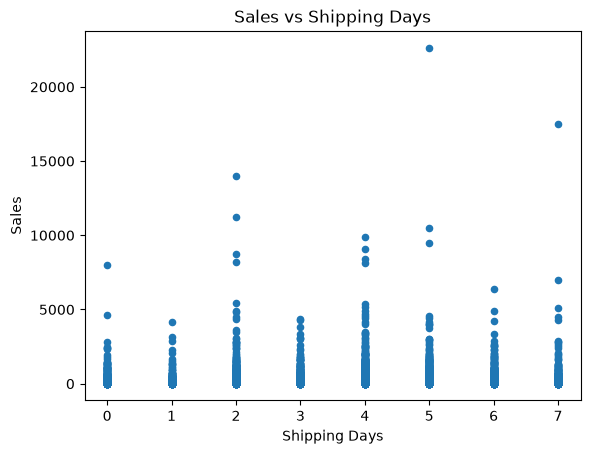

In [155]:
# Relationship analysis
import matplotlib.pyplot as plt
df.plot(
    kind="scatter",
    x="Shipping_Days",
    y="Sales"
)

plt.title("Sales vs Shipping Days")
plt.xlabel("Shipping Days")
plt.ylabel("Sales")
plt.show()